# Notebook 4: Evaluation of Results

The purpose of this notebook is to compare the timing resolution results of all methods on the same test events, determine how the incidence angle effects the performance of each method and to find out the features that have the most relevance.

## Setup; compatibility patch for SHAP

In [1]:
path = '/usr/local/lib/python3.10/dist-packages/shap/explainers/_tree.py'
with open(path) as f:
    src = f.read()

patches = [
    (
        '        self.base_score = float(learner_model_param["base_score"])',
        '        _bs = learner_model_param["base_score"]\n'
        '        if isinstance(_bs, str) and _bs.strip().startswith("["):\n'
        '            import json as _json\n'
        '            _bs = _json.loads(_bs)\n'
        '        if isinstance(_bs, (list, tuple)):\n'
        '            _bs = float(_bs[0])\n'
        '        else:\n'
        '            _bs = float(_bs)\n'
        '        self.base_score = _bs'
    ),
    (
        '        base_score = float(learner_model_param["base_score"])',
        '        base_score = learner_model_param["base_score"]\n'
        '        if isinstance(base_score, str) and base_score.strip().startswith("["):\n'
        '            import json as _json\n'
        '            base_score = _json.loads(base_score)\n'
        '        if isinstance(base_score, (list, tuple)):\n'
        '            base_score = float(base_score[0])\n'
        '        else:\n'
        '            base_score = float(base_score)'
    ),
]

already_patched_markers = [
    '_bs = learner_model_param["base_score"]',
    'if isinstance(base_score, str) and base_score.strip().startswith("[")',
]

n_applied = 0
for buggy_line, replacement in patches:
    if buggy_line in src:
        src = src.replace(buggy_line, replacement, 1)
        n_applied += 1

with open(path, 'w') as f:
    f.write(src)

n_present = sum(marker in src for marker in already_patched_markers)
print(f"Applied {n_applied} new patch(es) this run; {n_present}/2 patch markers now present in file.")

if n_present < 2:
    raise RuntimeError(
        "Not all expected patch targets were found or applied. Installed "
        f"shap source may differ from what's expected, inspect {path} "
        "around 'base_score' manually (search for 'learner_model_param[\"base_score\"]')."
    )

Applied 2 new patch(es) this run; 2/2 patch markers now present in file.


## Imports

In [2]:
import sys
sys.path.insert(0, '../src')

import os
import pickle
import json
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import shap
from xgboost import XGBRegressor
from metrics import fit_resolution

os.makedirs('plots', exist_ok=True)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the test-set results and align them

The CFD results are stored for all events while the ML results are only for the test events. Both files keep `orig_idx` and the row number in `hits.h5`. From the CFD arrays only the rows that were in the test set are picked. In this way the different methods can be compared on the same events.

In [3]:
#CFD results
with h5py.File('data/derived/cfd_baseline.h5', 'r') as f:
    orig_idx_cfd      = np.array(f['orig_idx'])
    delta_t_cfd_full  = np.array(f['delta_t'])
    delta_t_cfd1_full = np.array(f['delta_t_cfd1'])
    delta_t_cfd2_full = np.array(f['delta_t_cfd2'])

#ML results
with h5py.File('data/derived/ml_correction.h5', 'r') as f:
    orig_idx_ml = np.array(f['orig_idx'])
    delta_t_raw = np.array(f['delta_t'])
    delta_t_ml  = np.array(f['delta_t_ml'])

cfd_lookup = {idx: i for i, idx in enumerate(orig_idx_cfd)}
cfd_positions = np.array([cfd_lookup[i] for i in orig_idx_ml])

delta_t_cfd1_te = delta_t_cfd1_full[cfd_positions]
delta_t_cfd2_te = delta_t_cfd2_full[cfd_positions]

assert np.allclose(delta_t_cfd_full[cfd_positions], delta_t_raw), \
    "raw delta_t mismatch between cfd_baseline.h5 and ml_correction.h5 for the same orig_idx!"

print(f"Aligned {len(orig_idx_ml)} test-set hits across CFD and ML outputs")

#Angle of each test event
with h5py.File('../data/hits.h5', 'r') as f:
    angle_deg_all = np.array(f['angle_deg'])
angle_deg_te = angle_deg_all[orig_idx_ml]

Aligned 12885 test-set hits across CFD and ML outputs


## Rebuild the test features and check the saved model

The model needs the scaled test features for SHAP.

In [4]:
with open('models/scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)
with open('models/feature_cols.pkl', 'rb') as f:
    feature_cols = pickle.load(f)

with h5py.File('../data/hits.h5', 'r') as f:
    raw_cols = {k: np.array(f[k])[orig_idx_ml] for k in
                ['pulse_integral', 'pixel_charge', 'cluster_charge',
                 'cluster_size', 'col_frac', 'row_frac', 'angle_deg', 'v_bias']}

df_te = pd.DataFrame(raw_cols)
df_te['inv_pulse_integral'] = 1.0 / df_te['pulse_integral']
df_te['charge_per_pixel']   = df_te['cluster_charge'] / df_te['cluster_size']

X_te_reconstructed = df_te[feature_cols].values
X_te_s = scaler.transform(X_te_reconstructed)

model = XGBRegressor()
model.load_model('models/xgb_model.json')

check_pred = delta_t_raw - model.predict(X_te_s)
assert np.allclose(check_pred, delta_t_ml, atol=1e-2), \
    "Reconstructed X_te_s doesn't reproduce the saved ML correction!"
print("X_te_s reconstruction verified against saved ML correction.")

X_te_s reconstruction verified against saved ML correction.


## Result 1: residual distributions of all methods

Raw                    mu=  285.2 ps   sigma=  61.1 ps
CFD 1/PI (global)      mu=    0.5 ps   sigma=  55.0 ps
CFD per-angle          mu=    0.5 ps   sigma=  54.9 ps
XGBoost ML             mu=   -0.6 ps   sigma=  32.8 ps


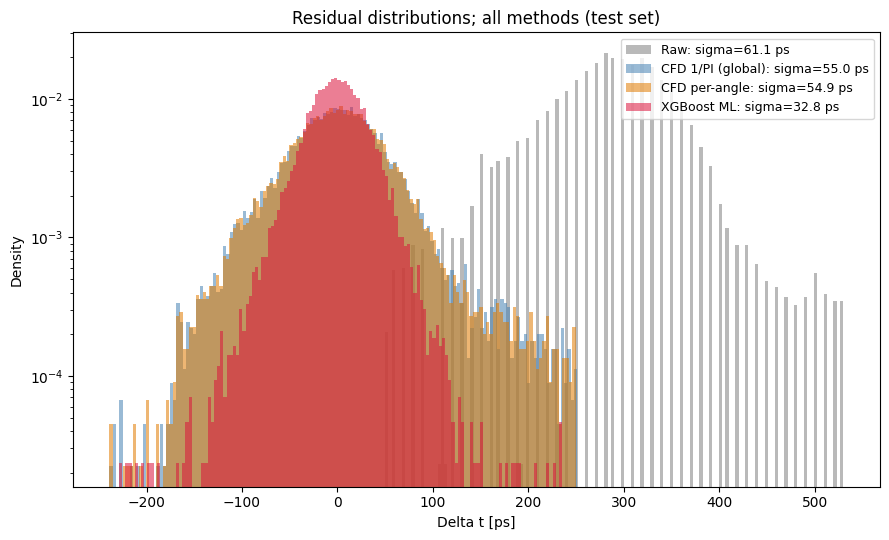

In [5]:
methods = {
    'Raw':               delta_t_raw,
    'CFD 1/PI (global)': delta_t_cfd1_te,
    'CFD per-angle':     delta_t_cfd2_te,
    'XGBoost ML':        delta_t_ml,
}
colors = ['grey', 'steelblue', '#E07B00', 'crimson']

sigmas = {}
fig, ax = plt.subplots(figsize=(9, 5.5))
for (label, res), color in zip(methods.items(), colors):
    mu, sigma = fit_resolution(res)
    print(f'{label:<22} mu={mu:7.1f} ps   sigma={sigma:6.1f} ps')
    sigmas[label] = sigma
    center = np.median(res)
    clipped = res[np.abs(res - center) < 250]
    ax.hist(clipped, bins=140, density=True, alpha=0.55, color=color,
            label=f'{label}: sigma={sigma:.1f} ps')

ax.set_yscale('log')
ax.set_xlabel('Delta t [ps]')
ax.set_ylabel('Density')
ax.set_title('Residual distributions; all methods (test set)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('plots/07_all_methods_comparison.pdf', dpi=150)
plt.show()

The XGBoost residuals represented in red form the narrowest and tallest peak with σ_t = 32.8 ps. The CFD results are very similar to each other while the raw data is shifted to the right and has the highest σ_t. For the ML correction the tail on the right side of the peak falls faster than the CFD tails so the ML method reduces also the late events. From this plot it can be seen that the ML model gives the best results .

## Result 2: time resolution vs incidence angle

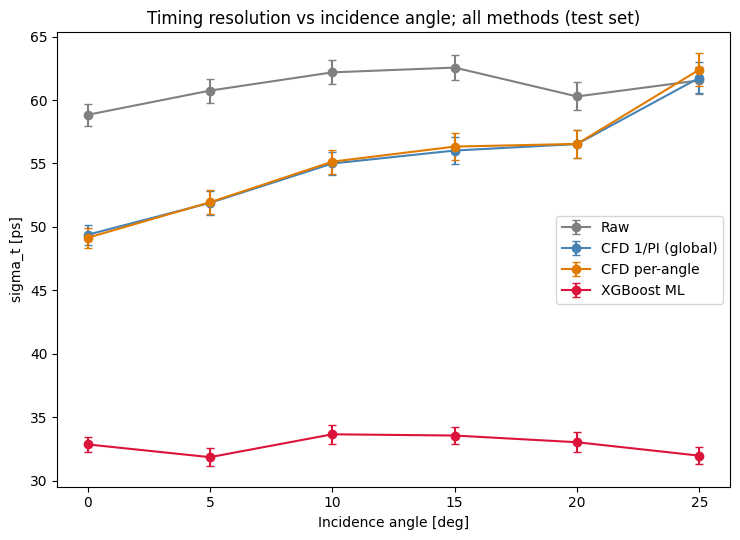

In [6]:
angles = sorted(np.unique(angle_deg_te))


def bootstrap_sigma_err(res, n_boot=200, seed=42):
    """
    Statistical uncertainty of sigma_t in ps.

    Resamples the residuals with replacement n_boot times, fits sigma_t on each resample and returns the standard deviation of those sigma_t values.
    """
    rng = np.random.default_rng(seed)
    sigmas_boot = [fit_resolution(rng.choice(res, size=len(res), replace=True))[1]
                   for _ in range(n_boot)]
    return np.std(sigmas_boot)


#sigma_t and its uncertainty for every method and for the events of each angle
sigma_by_angle     = {label: [] for label in methods}
sigma_err_by_angle = {label: [] for label in methods}
for a in angles:
    mask = angle_deg_te == a
    for label, res in methods.items():
        _, s = fit_resolution(res[mask])
        sigma_by_angle[label].append(s)
        sigma_err_by_angle[label].append(bootstrap_sigma_err(res[mask]))


fig, ax = plt.subplots(figsize=(7.5, 5.5))
for (label, sig_list), color in zip(sigma_by_angle.items(), colors):
    ax.errorbar(angles, sig_list, yerr=sigma_err_by_angle[label],
                fmt='o-', color=color, capsize=3, label=label)

ax.set_xlabel('Incidence angle [deg]')
ax.set_ylabel('sigma_t [ps]')
ax.set_title('Timing resolution vs incidence angle; all methods (test set)')
ax.legend()
plt.tight_layout()
plt.savefig('plots/08_sigma_vs_angle_all_methods.pdf', dpi=150)
plt.savefig('plots/08_sigma_vs_angle_all_methods.png', dpi=150)
plt.show()

XGBoost values stay about the same for all angles as it fluctuates between 30 and 35°. The raw data is also stable at around 60°. For the CFD results as the incidence angle increases there is a significant rise from about 50° to over 60°. The CFD correction works well at smaller incidence values but it loses it advantage at steeper angles. The ML correction has the same resolution at all angles and it is the preferred method.

## Result 3: SHAP feature importance

For every event SHAP assigns to every feature how much it moved the prediction. The bar chart shows the mean absolute value in ps. This is computed on the first 2000 test events.

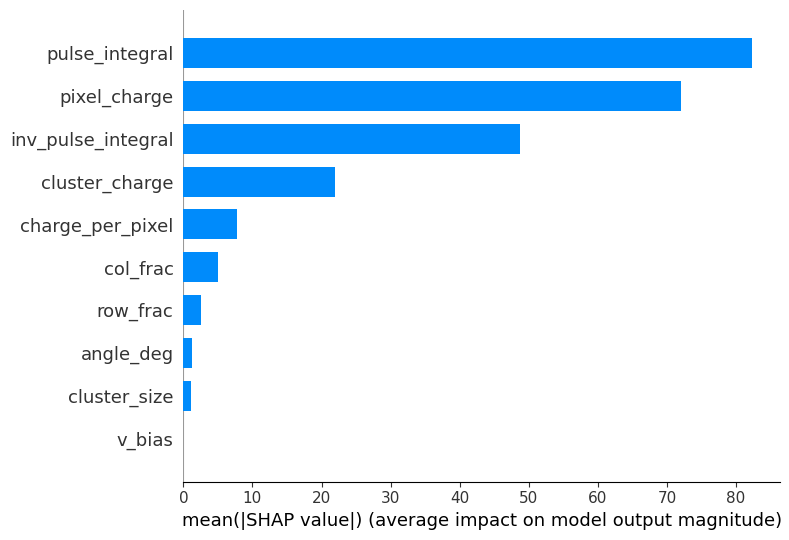

In [7]:
explainer = shap.TreeExplainer(model)
n_shap = min(2000, X_te_s.shape[0])
shap_values = explainer.shap_values(X_te_s[:n_shap])

plt.figure()
shap.summary_plot(shap_values, X_te_s[:n_shap],
                   feature_names=feature_cols,
                   plot_type='bar', show=False)
plt.tight_layout()
plt.savefig('plots/09_shap_importance.pdf', dpi=150)
plt.show()

From this it can be seen that the features that determine the amplitude such as `pulse_integral`, `pixel_charge` and `inv_pulse_integral` have the most impact as this forms the basis of the time-walk effect. Pixel edges also contribute in a small way. `col_frac` plays a bigger role than `row_frac` which was observed in Notebook 1 with the beam being tilted in x. Charge sharing has a bigger impact as represented by `cluster_charge` and `charge_per_pixel`.

## Result 4: summary table

Method                  sigma_t [ps]      vs Raw   vs best CFD
Raw                             61.1        0.0%             –
CFD 1/PI (global)               55.0       10.0%         -0.1%
CFD per-angle                   54.9       10.1%          0.0%
XGBoost ML                      32.8       46.2%         40.2%


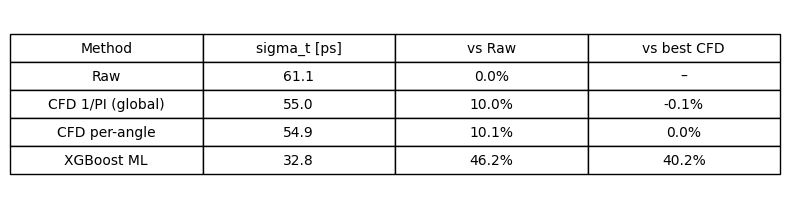

In [8]:
import csv

sigma_raw_val = sigmas['Raw']
best_cfd = min(sigmas['CFD 1/PI (global)'], sigmas['CFD per-angle'])


table_rows = []
for label, sigma in sigmas.items():
    imp_raw = 100 * (sigma_raw_val - sigma) / sigma_raw_val
    imp_cfd = None if label == 'Raw' else 100 * (best_cfd - sigma) / best_cfd
    table_rows.append((label, sigma, imp_raw, imp_cfd))


def fmt_pct(x):
    return '–' if x is None else f'{x:.1f}%'


print(f'{"Method":<22}{"sigma_t [ps]":>14}{"vs Raw":>12}{"vs best CFD":>14}')
for label, sigma, imp_raw, imp_cfd in table_rows:
    print(f'{label:<22}{sigma:>14.1f}{fmt_pct(imp_raw):>12}{fmt_pct(imp_cfd):>14}')


os.makedirs('data/derived', exist_ok=True)
with open('data/derived/final_results.pkl', 'wb') as f:
    pickle.dump(sigmas, f)


with open('data/derived/final_results.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['method', 'sigma_t_ps', 'improvement_vs_raw_pct', 'improvement_vs_best_cfd_pct'])
    for label, sigma, imp_raw, imp_cfd in table_rows:
        writer.writerow([label, f'{sigma:.1f}', f'{imp_raw:.1f}',
                         '' if imp_cfd is None else f'{imp_cfd:.1f}'])


fig, ax = plt.subplots(figsize=(8, 2.2))
ax.axis('off')
tbl = ax.table(
    cellText=[[label, f'{sigma:.1f}', fmt_pct(imp_raw), fmt_pct(imp_cfd)]
              for label, sigma, imp_raw, imp_cfd in table_rows],
    colLabels=['Method', 'sigma_t [ps]', 'vs Raw', 'vs best CFD'],
    loc='center', cellLoc='center',
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)
plt.tight_layout()
plt.savefig('plots/10_summary_table.pdf', dpi=150)
plt.savefig('plots/10_summary_table.png', dpi=150)
plt.show()